In [1]:
import duckdb

In [2]:
import os
os.listdir('D:/akiml_data/vitaldb')

['.ipynb_checkpoints',
 '01-vitaldb-explore.ipynb',
 'clinical_data.csv',
 'clinical_parameters.csv',
 'lab_data.csv',
 'lab_parameters.csv',
 'track_names.csv',
 'Untitled.ipynb']

In [3]:
duckdb.sql("SELECT COUNT(*) AS n FROM 'D:/akiml_data/vitaldb/clinical_data.csv'").df()

,n
0,6388


In [4]:
duckdb.sql("SELECT * FROM 'D:/akiml_data/vitaldb/lab_parameters.csv'").df()

,Parameter,Category,Description,Unit,Reference value
0,wbc,CBC,White blood cell count,×1000/mcL,4~10
1,hb,CBC,Hemoglobin,g/dL,13~17
2,hct,CBC,Hematocrit,%,39~52
3,plt,CBC,Platelet count,×1000/mcL,130~400
4,esr,CBC,Erythrocyte sedimentation rate,mm/hr,0~9
5,gluc,Chemistry,Glucose,mg/dL,70~110
6,tprot,Chemistry,Total protein,g/dL,6.0~8.0
7,alb,Chemistry,Albumin,g/dL,3.3~5.2
8,tbil,Chemistry,Total bilirubin,mg/dL,0.2~1.2
9,ast,Chemistry,Asparate transferase,IU/L,1~40


In [5]:
duckdb.sql("SELECT * FROM 'D:/akiml_data/vitaldb/lab_data.csv' LIMIT 5").df()

,caseid,dt,name,result
0,1,594470,alb,2.9
1,1,399575,alb,3.2
2,1,12614,alb,3.4
3,1,137855,alb,3.6
4,1,399575,alt,12.0


In [6]:
duckdb.sql("SELECT COUNT(*) AS n_cre FROM 'D:/akiml_data/vitaldb/lab_data.csv' WHERE name = 'CRE'").df()

,n_cre
0,0


In [7]:
duckdb.sql("SELECT * FROM 'D:/akiml_data/vitaldb/clinical_data.csv' LIMIT 3").df()

,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,intraop_colloid,intraop_ppf,intraop_mdz,intraop_ftn,intraop_rocu,intraop_vecu,intraop_eph,intraop_phe,intraop_epi,intraop_ca
0,1,5955,0,11542,-552,10848.0,1668,10368,-236220,627780,...,0,120,0.0,100,70,0,10,0,0,0
1,2,2487,0,15741,-1039,14921.0,1721,14621,-221160,1506840,...,0,150,0.0,0,100,0,20,0,0,0
2,3,2861,0,4394,-590,4210.0,1090,3010,-218640,40560,...,0,0,0.0,0,50,0,0,0,0,0


In [8]:
duckdb.sql("SELECT DISTINCT name FROM 'D:/akiml_data/vitaldb/lab_data.csv' ORDER BY name").df()

,name
0,alb
1,alt
2,ammo
3,aptt
4,ast
5,be
6,bun
7,ccr
8,cl
9,cr


In [9]:
duckdb.sql("""
SELECT COUNT(*) AS n, MIN(result) AS min_val, MAX(result) AS max_val, AVG(result) AS mean_val
FROM 'D:/akiml_data/vitaldb/lab_data.csv'
WHERE name = 'cre'
""").df()

,n,min_val,max_val,mean_val
0,0,NaN,NaN,NaN


In [10]:
duckdb.sql("""
SELECT COUNT(*) AS n, MIN(result) AS min_val, MAX(result) AS max_val, AVG(result) AS mean_val
FROM 'D:/akiml_data/vitaldb/lab_data.csv'
WHERE name = 'cr'
""").df()

,n,min_val,max_val,mean_val
0,37311,0.02,64.88,1.314156


In [11]:
duckdb.sql("""
SELECT l.caseid, l.dt, l.result, c.opstart, c.opend,
       (l.dt - c.opstart)/3600.0 AS hours_from_opstart
FROM 'D:/akiml_data/vitaldb/lab_data.csv' l
JOIN 'D:/akiml_data/vitaldb/clinical_data.csv' c ON l.caseid = c.caseid
WHERE l.name = 'cr'
LIMIT 10
""").df()

,caseid,dt,result,opstart,opend,hours_from_opstart
0,1,594470,0.72,1668,10368,164.667222
1,1,399575,0.75,1668,10368,110.529722
2,1,12614,0.88,1668,10368,3.040556
3,1,137855,0.91,1668,10368,37.829722
4,2,502448,0.71,1721,14621,139.090833
5,2,326060,0.76,1721,14621,90.094167
6,2,240320,0.77,1721,14621,66.277500
7,2,5857898,0.82,1721,14621,1626.715833
8,2,5776336,0.98,1721,14621,1604.059722
9,2,152248,1.02,1721,14621,41.813056


In [12]:
duckdb.sql("""
WITH cr AS (
  SELECT l.caseid, l.dt, l.result AS cr_val, c.opstart, c.opend
  FROM 'D:/akiml_data/vitaldb/lab_data.csv' l
  JOIN 'D:/akiml_data/vitaldb/clinical_data.csv' c ON l.caseid = c.caseid
  WHERE l.name = 'cr' AND l.result BETWEEN 0.2 AND 25
),
base AS (
  SELECT caseid, cr_val AS baseline_cr
  FROM (
    SELECT caseid, dt, cr_val,
           ROW_NUMBER() OVER (PARTITION BY caseid ORDER BY dt DESC) AS rn
    FROM cr
    WHERE dt <= opstart AND dt >= opstart - 7*86400
  ) WHERE rn = 1
),
post AS (
  SELECT caseid, MAX(cr_val) AS postop_cr_max
  FROM cr
  WHERE dt >= opend AND dt <= opend + 7*86400
  GROUP BY caseid
)
SELECT
  COUNT(*) AS n_with_baseline,
  COUNT(post.caseid) AS n_with_postop_cr,
  SUM(CASE WHEN postop_cr_max >= GREATEST(baseline_cr*1.5, baseline_cr+0.3) THEN 1 ELSE 0 END) AS n_aki
FROM base LEFT JOIN post USING (caseid)
""").df()

,n_with_baseline,n_with_postop_cr,n_aki
0,3741,3103,105.0


In [13]:
duckdb.sql("""
SELECT
  COUNT(*) AS n,
  ROUND(MEDIAN(baseline_cr),2) AS median_base,
  ROUND(QUANTILE_CONT(baseline_cr, 0.05),2) AS p05,
  ROUND(QUANTILE_CONT(baseline_cr, 0.25),2) AS p25
FROM (
  SELECT l.caseid, l.result AS baseline_cr,
         ROW_NUMBER() OVER (PARTITION BY l.caseid ORDER BY l.dt DESC) AS rn
  FROM 'D:/akiml_data/vitaldb/lab_data.csv' l
  JOIN 'D:/akiml_data/vitaldb/clinical_data.csv' c ON l.caseid = c.caseid
  WHERE l.name='cr' AND l.result BETWEEN 0.2 AND 25
    AND l.dt <= c.opstart AND l.dt >= c.opstart - 7*86400
) WHERE rn = 1
""").df()

InternalException: INTERNAL Error: Failed to cast expression to type - expression type mismatch
This error signals an assertion failure within DuckDB. This usually occurs due to unexpected conditions or errors in the program's logic.
For more information, see https://duckdb.org/docs/stable/dev/internal_errors

In [ ]:
duckdb.sql("""
WITH cr AS (
  SELECT l.caseid, l.dt, l.result AS cr_val, c.opstart, c.opend
  FROM 'D:/akiml_data/vitaldb/lab_data.csv' l
  JOIN 'D:/akiml_data/vitaldb/clinical_data.csv' c ON l.caseid = c.caseid
  WHERE l.name='cr' AND l.result BETWEEN 0.2 AND 25
),
base AS (
  SELECT caseid, cr_val AS baseline_cr
  FROM (SELECT caseid, dt, cr_val,
        ROW_NUMBER() OVER (PARTITION BY caseid ORDER BY dt DESC) rn
        FROM cr WHERE dt <= opstart AND dt >= opstart - 7*86400)
  WHERE rn = 1
),
flag AS (
  SELECT cr.caseid,
    MAX(CASE WHEN cr.dt >= cr.opend AND cr.dt <= cr.opend + 2*86400
              AND cr_val >= base.baseline_cr + 0.3 THEN 1 ELSE 0 END) AS crit_48h,
    MAX(CASE WHEN cr.dt >= cr.opend AND cr.dt <= cr.opend + 7*86400
              AND cr_val >= base.baseline_cr * 1.5 THEN 1 ELSE 0 END) AS crit_7d
  FROM cr JOIN base ON cr.caseid = base.caseid
  GROUP BY cr.caseid
)
SELECT
  COUNT(*) AS n_total,
  SUM(crit_48h) AS n_aki_48h,
  SUM(crit_7d) AS n_aki_7d,
  SUM(CASE WHEN crit_48h=1 OR crit_7d=1 THEN 1 ELSE 0 END) AS n_aki_kdigo
FROM base LEFT JOIN flag USING (caseid)
""").df()

In [ ]:
duckdb.sql("""
SELECT CASE WHEN baseline_cr < 0.5 THEN 'a.<0.5'
            WHEN baseline_cr < 0.7 THEN 'b.0.5-0.7'
            WHEN baseline_cr < 1.0 THEN 'c.0.7-1.0'
            WHEN baseline_cr < 1.5 THEN 'd.1.0-1.5'
            ELSE 'e.>=1.5' END AS base_grp,
       COUNT(*) AS n
FROM (
  SELECT l.caseid, l.result AS baseline_cr,
         ROW_NUMBER() OVER (PARTITION BY l.caseid ORDER BY l.dt DESC) AS rn
  FROM 'D:/akiml_data/vitaldb/lab_data.csv' l
  JOIN 'D:/akiml_data/vitaldb/clinical_data.csv' c ON l.caseid = c.caseid
  WHERE l.name='cr' AND l.result BETWEEN 0.2 AND 25
    AND l.dt <= c.opstart AND l.dt >= c.opstart - 7*86400
) WHERE rn = 1
GROUP BY 1 ORDER BY 1
""").df()

In [14]:
base = duckdb.sql("""
WITH cr AS (
  SELECT l.caseid, l.dt, l.result AS cr_val, c.opstart
  FROM 'D:/akiml_data/vitaldb/lab_data.csv' l
  JOIN 'D:/akiml_data/vitaldb/clinical_data.csv' c ON l.caseid = c.caseid
  WHERE l.name='cr' AND l.result BETWEEN 0.2 AND 25
)
SELECT caseid, cr_val AS baseline_cr
FROM (
  SELECT caseid, dt, cr_val,
         ROW_NUMBER() OVER (PARTITION BY caseid ORDER BY dt DESC) AS rn
  FROM cr
  WHERE dt <= opstart AND dt >= opstart - 7*86400
) WHERE rn = 1
""").df()

InternalException: INTERNAL Error: Failed to cast expression to type - expression type mismatch
This error signals an assertion failure within DuckDB. This usually occurs due to unexpected conditions or errors in the program's logic.
For more information, see https://duckdb.org/docs/stable/dev/internal_errors

In [15]:
import pandas as pd

lab = pd.read_csv('D:/akiml_data/vitaldb/lab_data.csv')
clin = pd.read_csv('D:/akiml_data/vitaldb/clinical_data.csv')

cr = lab[lab['name'] == 'cr'].merge(
    clin[['caseid','opstart','opend']], on='caseid', how='inner')
cr = cr[(cr['result'] >= 0.2) & (cr['result'] <= 25)].copy()

pre = cr[(cr['dt'] <= cr['opstart']) & (cr['dt'] >= cr['opstart'] - 7*86400)]
base = (pre.sort_values('dt', ascending=False)
            .drop_duplicates('caseid')[['caseid','result']]
            .rename(columns={'result':'baseline_cr'}))

base['bucket'] = pd.cut(base['baseline_cr'], bins=[0,0.5,0.7,1.0,1.5,99],
                        labels=['<0.5','0.5-0.7','0.7-1.0','1.0-1.5','>=1.5'],
                        right=False)
base['bucket'].value_counts().sort_index()

bucket
<0.5        128
0.5-0.7    1026
0.7-1.0    1708
1.0-1.5     557
>=1.5       322
Name: count, dtype: int64

In [16]:
post = cr[(cr['dt'] >= cr['opend']) & (cr['dt'] <= cr['opend'] + 7*86400)]
postmax = post.groupby('caseid')['result'].max().rename('postop_cr_max')

df = base.merge(postmax, on='caseid', how='left')
df['aki_48h'] = ((df['postop_cr_max'] >= df['baseline_cr'] + 0.3)).astype(float)
df['aki_7d']  = ((df['postop_cr_max'] >= df['baseline_cr'] * 1.5)).astype(float)
df['aki'] = ((df['aki_48h'] == 1) | (df['aki_7d'] == 1)).astype(int)

print(len(df), df['aki'].sum(), round(df['aki'].mean()*100, 1), '%')

3741 216 5.8 %


In [17]:
post48 = cr[(cr['dt'] >= cr['opend']) & (cr['dt'] <= cr['opend'] + 2*86400)]
max48 = post48.groupby('caseid')['result'].max().rename('cr_max_48h')

post7 = cr[(cr['dt'] >= cr['opend']) & (cr['dt'] <= cr['opend'] + 7*86400)]
max7 = post7.groupby('caseid')['result'].max().rename('cr_max_7d')

df = (base.merge(max48, on='caseid', how='left')
          .merge(max7, on='caseid', how='left'))
df['aki'] = ((df['cr_max_48h'] >= df['baseline_cr'] + 0.3) |
             (df['cr_max_7d'] >= df['baseline_cr'] * 1.5)).astype(int)
print(len(df), df['aki'].sum(), round(100*df['aki'].mean(), 1), '%')

3741 195 5.2 %


In [18]:
duckdb.sql("""
WITH cr AS (
  SELECT l.caseid, l.dt, l.result AS cr_val, c.opstart, c.opend
  FROM 'D:/akiml_data/vitaldb/lab_data.csv' l
  JOIN 'D:/akiml_data/vitaldb/clinical_data.csv' c ON l.caseid = c.caseid
  WHERE l.name='cr' AND l.result BETWEEN 0.2 AND 25
),
base AS (
  SELECT caseid, cr_val AS baseline_cr FROM (
    SELECT caseid, dt, cr_val,
           ROW_NUMBER() OVER (PARTITION BY caseid ORDER BY dt DESC) rn
    FROM cr WHERE dt <= opstart AND dt >= opstart - 7*86400
  ) WHERE rn = 1
),
post AS (
  SELECT caseid, MAX(cr_val) AS postop_max, COUNT(*) AS n_postop_meas
  FROM cr WHERE dt >= opend AND dt <= opend + 7*86400
  GROUP BY caseid
)
SELECT b.caseid,
       ROUND(b.baseline_cr, 2) AS baseline_cr,
       ROUND(p.postop_max, 2) AS postop_cr_max,
       p.n_postop_meas,
       CASE WHEN p.postop_max >= b.baseline_cr * 1.5 THEN 'AKI_1.5x' ELSE 'no' END AS flag
FROM base b
JOIN post p USING (caseid)
ORDER BY p.postop_max DESC
LIMIT 20
""").df()

,caseid,baseline_cr,postop_cr_max,n_postop_meas,flag
0,988,0.72,22.54,9,AKI_1.5x
1,4862,21.45,22.45,1,no
2,4708,21.92,20.80,5,no
3,4835,17.67,18.13,8,no
4,4650,19.99,17.48,8,no
5,5669,18.10,16.64,8,no
6,309,13.86,16.63,4,no
7,3323,16.44,16.06,1,no
8,1548,17.51,15.94,8,no
9,58,17.05,15.83,9,no


In [19]:
base = base[base['baseline_cr'] < 4.0].copy()   # 排除CKD4-5（相当于eGFR<30）

In [20]:
df = (base.merge(max48, on='caseid', how='left')
          .merge(max7, on='caseid', how='left'))
df['aki'] = ((df['cr_max_48h'] >= df['baseline_cr'] + 0.3) |
             (df['cr_max_7d'] >= df['baseline_cr'] * 1.5)).astype(int)
print(len(df), df['aki'].sum(), round(100*df['aki'].mean(), 1), '%')

3534 155 4.4 %


In [21]:
cr[cr['caseid'] == 988].sort_values('dt')[['dt','result','opstart','opend']]

,dt,result,opstart,opend
5671,-321711,0.72,2224,14224
5676,69720,2.03,2224,14224
5678,91432,22.54,2224,14224
5677,92755,2.37,2224,14224
5675,119960,1.96,2224,14224
5673,156806,1.05,2224,14224
5674,162887,1.57,2224,14224
5670,243569,0.71,2224,14224
5669,342883,0.59,2224,14224
5672,415649,0.73,2224,14224


In [22]:
crb = cr.merge(base[['caseid','baseline_cr']], on='caseid', how='inner')
p48 = crb[(crb['dt'] >= crb['opend']) & (crb['dt'] <= crb['opend'] + 2*86400)]
p7  = crb[(crb['dt'] >= crb['opend']) & (crb['dt'] <= crb['opend'] + 7*86400)]
n48 = p48[p48['result'] >= p48['baseline_cr'] + 0.3].groupby('caseid').size()
n7  = p7[p7['result'] >= p7['baseline_cr'] * 1.5].groupby('caseid').size()

df2 = base[['caseid','baseline_cr']].copy()
df2['n_elev48'] = df2['caseid'].map(n48).fillna(0).astype(int)
df2['n_elev7']  = df2['caseid'].map(n7).fillna(0).astype(int)
df2['aki_confirmed'] = ((df2['n_elev48'] >= 2) | (df2['n_elev7'] >= 2)).astype(int)
print(len(df2), df2['aki_confirmed'].sum(), round(100*df2['aki_confirmed'].mean(),1), '%')

3534 87 2.5 %


In [23]:
p7.groupby('caseid').size().describe()

count    2924.000000
mean        4.282832
std         3.445142
min         1.000000
25%         2.000000
50%         4.000000
75%         5.000000
max        39.000000
dtype: float64

In [25]:
import pandas as pd

# 74 个变量的字典
params = pd.read_csv('D:/akiml_data/vitaldb/clinical_parameters.csv')
params

,Parameter,Data Source,Description,Unit
0,caseid,Random,Case ID; Random number between 00001 and 06388,NaN
1,subjectid,EMR,Subject ID; Deidentified hospital ID of patient,NaN
2,casestart,Case file,Recording Start Time; Set to 0 for anonymization,sec
3,caseend,Case file,Recording End Time; from casestart,sec
4,anestart,Case file,Anesthesia start time; from casestart,sec
...,...,...,...,...
76,intraop_vecu,EMR,Vecuronium,mg
77,intraop_eph,EMR,Ephedrine,mg
78,intraop_phe,EMR,Phenylephrine,mcg
79,intraop_epi,EMR,Epinephrine,mcg


In [26]:
# clinical_data 的实际列名 + 前 3 行 glimpse
clin = pd.read_csv('D:/akiml_data/vitaldb/clinical_data.csv')
list(clin.columns)

['caseid',
 'subjectid',
 'casestart',
 'caseend',
 'anestart',
 'aneend',
 'opstart',
 'opend',
 'adm',
 'dis',
 'icu_days',
 'death_inhosp',
 'age',
 'sex',
 'height',
 'weight',
 'bmi',
 'asa',
 'emop',
 'department',
 'optype',
 'dx',
 'opname',
 'approach',
 'position',
 'ane_type',
 'preop_htn',
 'preop_dm',
 'preop_ecg',
 'preop_pft',
 'preop_hb',
 'preop_plt',
 'preop_pt',
 'preop_aptt',
 'preop_na',
 'preop_k',
 'preop_gluc',
 'preop_alb',
 'preop_ast',
 'preop_alt',
 'preop_bun',
 'preop_cr',
 'preop_ph',
 'preop_hco3',
 'preop_be',
 'preop_pao2',
 'preop_paco2',
 'preop_sao2',
 'cormack',
 'airway',
 'tubesize',
 'dltubesize',
 'lmasize',
 'iv1',
 'iv2',
 'aline1',
 'aline2',
 'cline1',
 'cline2',
 'intraop_ebl',
 'intraop_uo',
 'intraop_rbc',
 'intraop_ffp',
 'intraop_crystalloid',
 'intraop_colloid',
 'intraop_ppf',
 'intraop_mdz',
 'intraop_ftn',
 'intraop_rocu',
 'intraop_vecu',
 'intraop_eph',
 'intraop_phe',
 'intraop_epi',
 'intraop_ca']

In [27]:
preop_vars = ['age','sex','height','weight','bmi','asa','emop','preop_dm','preop_htn',
              'department','optype','approach','ane_type',
              'preop_hb','preop_plt','preop_pt','preop_aptt','preop_na','preop_k',
              'preop_gluc','preop_alb','preop_bun','preop_cr']

outcome = (base[['caseid','baseline_cr']]
           .merge(max48, on='caseid', how='left')
           .merge(max7,  on='caseid', how='left'))
outcome['aki'] = ((outcome['cr_max_48h'] >= outcome['baseline_cr'] + 0.3) |
                  (outcome['cr_max_7d']  >= outcome['baseline_cr'] * 1.5)).astype(int)

model_df = outcome.merge(clin[['caseid'] + preop_vars], on='caseid', how='left')

summary = pd.DataFrame({
    'dtype': model_df.dtypes.astype(str),
    'n_miss': model_df.isna().sum(),
    'miss_%': (100 * model_df.isna().mean()).round(1)
})
summary

,dtype,n_miss,miss_%
caseid,int64,0,0.0
baseline_cr,float64,0,0.0
cr_max_48h,float64,661,18.7
cr_max_7d,float64,610,17.3
aki,int64,0,0.0
age,object,0,0.0
sex,object,0,0.0
height,float64,0,0.0
weight,float64,0,0.0
bmi,float64,0,0.0


In [28]:
for c in ['sex','asa','emop','preop_dm','preop_htn','department','optype','approach','ane_type']:
    print(c, '| unique:', model_df[c].nunique(), '|', model_df[c].dropna().unique()[:8])

sex | unique: 2 | ['F' 'M']
asa | unique: 5 | [3. 2. 4. 1. 6.]
emop | unique: 2 | [0 1]
preop_dm | unique: 2 | [0 1]
preop_htn | unique: 2 | [0 1]
department | unique: 4 | ['General surgery' 'Thoracic surgery' 'Gynecology' 'Urology']
optype | unique: 11 | ['Transplantation' 'Others' 'Hepatic' 'Vascular' 'Biliary/Pancreas'
 'Stomach' 'Colorectal' 'Minor resection']
approach | unique: 3 | ['Open' 'Videoscopic' 'Robotic']
ane_type | unique: 3 | ['General' 'Spinal' 'Sedationalgesia']


In [29]:
chk = model_df[['baseline_cr','preop_cr']].dropna()
(chk['baseline_cr'] - chk['preop_cr']).abs().describe()

count    3238.000000
mean        0.043212
std         0.264841
min         0.000000
25%         0.000000
50%         0.000000
75%         0.020000
max        10.020000
dtype: float64

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

d = model_df.copy()
d = d[(d['age'] >= 18) & (d['age'] <= 100)]
d['bmi'] = d['bmi'].where(d['bmi'].between(10, 80))
d = d[d['asa'] <= 5]   # 排除ASA6（脑死亡捐献者）

num_vars = ['age','bmi','asa','preop_hb','preop_plt','preop_pt','preop_aptt',
            'preop_na','preop_k','preop_gluc','preop_alb','preop_bun','preop_cr']
cat_vars = ['sex','emop','preop_dm','preop_htn','department','optype','approach','ane_type']

X = d[num_vars + cat_vars]
y = d['aki']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_vars),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_vars),
])

TypeError: '>=' not supported between instances of 'str' and 'int'

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

lr = Pipeline([('pre', pre), ('m', LogisticRegression(max_iter=2000))])
lr.fit(Xtr, ytr)
p_lr = lr.predict_proba(Xte)[:, 1]
print('LR  AUROC:', round(roc_auc_score(yte, p_lr), 3),
      '| AUPRC:', round(average_precision_score(yte, p_lr), 3),
      '| Brier:', round(brier_score_loss(yte, p_lr), 4))

NameError: name 'Xtr' is not defined

In [32]:
d = model_df.copy()

# 类型修正：age 在 csv 里是字符串，先转数字（转不了的变缺失，稍后被过滤）
d['age'] = pd.to_numeric(d['age'], errors='coerce')
d['bmi'] = pd.to_numeric(d['bmi'], errors='coerce')

d = d[(d['age'] >= 18) & (d['age'] <= 100)]
d['bmi'] = d['bmi'].where(d['bmi'].between(10, 80))
d = d[d['asa'] <= 5]

num_vars = ['age','bmi','asa','preop_hb','preop_plt','preop_pt','preop_aptt',
            'preop_na','preop_k','preop_gluc','preop_alb','preop_bun','preop_cr']
cat_vars = ['sex','emop','preop_dm','preop_htn','department','optype','approach','ane_type']

X = d[num_vars + cat_vars]
y = d['aki']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_vars),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_vars),
])

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

lr = Pipeline([('pre', pre), ('m', LogisticRegression(max_iter=2000))])
lr.fit(Xtr, ytr)
p_lr = lr.predict_proba(Xte)[:, 1]
print('LR  AUROC:', round(roc_auc_score(yte, p_lr), 3),
      '| AUPRC:', round(average_precision_score(yte, p_lr), 3),
      '| Brier:', round(brier_score_loss(yte, p_lr), 4))

LR  AUROC: 0.845 | AUPRC: 0.269 | Brier: 0.0359


In [34]:
from xgboost import XGBClassifier

xgb = Pipeline([('pre', pre),
                ('m', XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                    subsample=0.8, colsample_bytree=0.8,
                                    random_state=42, eval_metric='aucpr'))])
xgb.fit(Xtr, ytr)
p_xgb = xgb.predict_proba(Xte)[:, 1]
print('XGB AUROC:', round(roc_auc_score(yte, p_xgb), 3),
      '| AUPRC:', round(average_precision_score(yte, p_xgb), 3),
      '| Brier:', round(brier_score_loss(yte, p_xgb), 4))

XGB AUROC: 0.741 | AUPRC: 0.194 | Brier: 0.0389


In [35]:
import numpy as np

def boot_auc(y_true, p, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    y = np.asarray(y_true); n = len(y)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y[idx].sum() in (0, n):
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 50, 97.5]).round(3)

print('LR  AUC 95%CI:', boot_auc(yte, p_lr))
print('XGB AUC 95%CI:', boot_auc(yte, p_xgb))

LR  AUC 95%CI: [0.784 0.846 0.899]
XGB AUC 95%CI: [0.656 0.745 0.829]


In [36]:
eps = 1e-6
pl = np.clip(p_lr, eps, 1-eps)
logit = np.log(pl/(1-pl)).reshape(-1, 1)
cal = LogisticRegression(max_iter=1000).fit(logit, yte)
print('校准斜率:', round(float(cal.coef_[0][0]), 3),
      '| 校准截距:', round(float(cal.intercept_[0]), 3))

校准斜率: 0.8 | 校准截距: -0.617


In [37]:
rng = np.random.default_rng(7)
n = len(yte); yv = np.asarray(yte)
pl_arr = np.asarray(p_lr); px_arr = np.asarray(p_xgb)
diffs = []
for _ in range(500):
    idx = rng.integers(0, n, n)
    if yv[idx].sum() in (0, n):
        continue
    diffs.append(roc_auc_score(yv[idx], pl_arr[idx]) - roc_auc_score(yv[idx], px_arr[idx]))
print('AUC差值(LR-XGB) 95%CI:', np.percentile(diffs, [2.5, 50, 97.5]).round(3))

AUC差值(LR-XGB) 95%CI: [0.05  0.104 0.165]


In [38]:
from sklearn.linear_model import LogisticRegressionCV

lr_cv = Pipeline([('pre', pre),
                  ('m', LogisticRegressionCV(Cs=20, cv=5, scoring='roc_auc',
                                             max_iter=3000, random_state=42))])
lr_cv.fit(Xtr, ytr)
p_cv = lr_cv.predict_proba(Xte)[:, 1]

print('LRcv AUROC:', round(roc_auc_score(yte, p_cv), 3),
      '| AUPRC:', round(average_precision_score(yte, p_cv), 3),
      '| Brier:', round(brier_score_loss(yte, p_cv), 4))
print('选中的正则强度 C =', lr_cv.named_steps['m'].C_[0])

# 新模型的校准评估
pl2 = np.clip(p_cv, 1e-6, 1-1e-6)
logit2 = np.log(pl2/(1-pl2)).reshape(-1, 1)
cal2 = LogisticRegression(max_iter=1000).fit(logit2, yte)
print('新校准斜率:', round(float(cal2.coef_[0][0]), 3),
      '| 新校准截距:', round(float(cal2.intercept_[0]), 3))

D:\Miniconda3\envs\akiml\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
D:\Miniconda3\envs\akiml\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


LRcv AUROC: 0.845 | AUPRC: 0.274 | Brier: 0.0357
选中的正则强度 C = 4.281332398719396
新校准斜率: 0.78 | 新校准截距: -0.664


In [39]:
from sklearn.model_selection import cross_val_predict

def logit(p):
    p = np.clip(p, 1e-6, 1-1e-6)
    return np.log(p/(1-p))

# 第一步：在训练集上做5折交叉验证，拿"样本外"预测（out-of-fold）
oof = cross_val_predict(lr_cv, Xtr, ytr, cv=5, method='predict_proba')[:, 1]

# 第二步：用训练集的 oof 预测拟合再校准参数 a（截距修正）和 b（斜率修正）
calib = LogisticRegression(max_iter=1000).fit(logit(oof).reshape(-1, 1), ytr)
a, b = float(calib.intercept_[0]), float(calib.coef_[0][0])
print('再校准参数：a =', round(a, 3), '| b =', round(b, 3))

# 第三步：应用到测试集
p_final = 1 / (1 + np.exp(-(a + b * logit(p_cv))))

print('再校准后 AUROC:', round(roc_auc_score(yte, p_final), 3),
      '| Brier:', round(brier_score_loss(yte, p_final), 4))

cal3 = LogisticRegression(max_iter=1000).fit(logit(p_final).reshape(-1, 1), yte)
print('最终校准斜率:', round(float(cal3.coef_[0][0]), 3),
      '| 最终校准截距:', round(float(cal3.intercept_[0]), 3))

D:\Miniconda3\envs\akiml\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
D:\Miniconda3\envs\akiml\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
D:\Miniconda3\envs\akiml\Lib\site-packages\sklearn\line

再校准参数：a = -0.555 | b = 0.785
再校准后 AUROC: 0.845 | Brier: 0.0355
最终校准斜率: 0.987 | 最终校准截距: -0.129


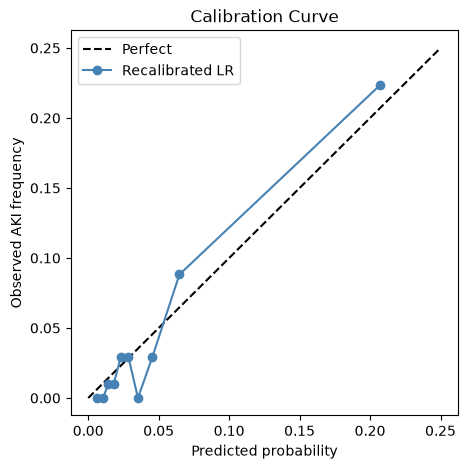

In [40]:
import matplotlib.pyplot as plt

tmp = pd.DataFrame({'y': np.asarray(yte), 'p': p_final})
tmp['bin'] = pd.qcut(tmp['p'], 10, duplicates='drop')
g = tmp.groupby('bin', observed=True).agg(pred=('p','mean'), obs=('y','mean'))

plt.figure(figsize=(5, 5))
plt.plot([0, 0.25], [0, 0.25], 'k--', label='Perfect')
plt.plot(g['pred'], g['obs'], 'o-', color='steelblue', label='Recalibrated LR')
plt.xlabel('Predicted probability'); plt.ylabel('Observed AKI frequency')
plt.legend(); plt.title('Calibration Curve'); plt.show()

ValueError: xmin must be a single scalar value, but got :

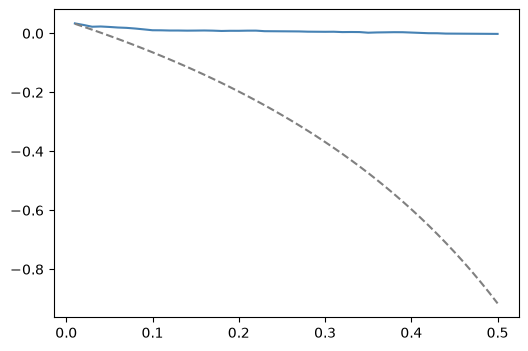

In [41]:
th = np.linspace(0.01, 0.50, 50)
y_arr = np.asarray(yte); n = len(y_arr); prev = y_arr.mean()
nb_m = [(((p_final>=t)&(y_arr==1)).sum()/n - ((p_final>=t)&(y_arr==0)).sum()/n*(t/(1-t))) for t in th]
nb_a = [prev - (1-prev)*(t/(1-t)) for t in th]

plt.figure(figsize=(6, 4))
plt.plot(th, nb_m, label='Model (recalibrated)', color='steelblue')
plt.plot(th, nb_a, '--', label='Treat all', color='gray')
plt.axhline(0, ':', color='black', label='Treat none')
plt.xlabel('Threshold probability'); plt.ylabel('Net benefit')
plt.legend(); plt.title('Decision Curve Analysis'); plt.show()

In [42]:
feat_names = lr_cv.named_steps['pre'].get_feature_names_out()
coefs = lr_cv.named_steps['m'].coef_[0]
coef_tbl = (pd.DataFrame({'feature': feat_names, 'beta': coefs})
            .assign(OR=lambda x: np.exp(x['beta']),
                    abs_beta=lambda x: x['beta'].abs())
            .sort_values('abs_beta', ascending=False)
            .drop(columns='abs_beta').reset_index(drop=True))
coef_tbl.head(20)

,feature,beta,OR
0,cat__department_Urology,1.563680,4.776367
1,cat__optype_Transplantation,1.497368,4.469909
2,cat__optype_Breast,-1.457846,0.232737
3,cat__ane_type_General,1.180604,3.256341
4,cat__department_Thoracic surgery,-0.855407,0.425110
5,cat__ane_type_Spinal,-0.844766,0.429658
6,cat__approach_Robotic,0.830495,2.294455
7,cat__department_Gynecology,-0.826179,0.437718
8,cat__optype_Thyroid,0.790080,2.203572
9,cat__approach_Videoscopic,-0.778922,0.458900


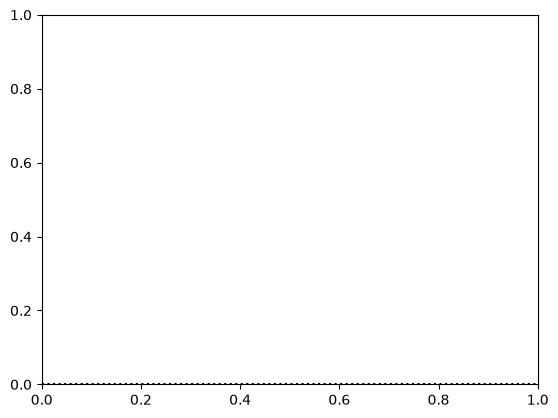

In [43]:
plt.axhline(0, linestyle=':', color='black', label='Treat none')

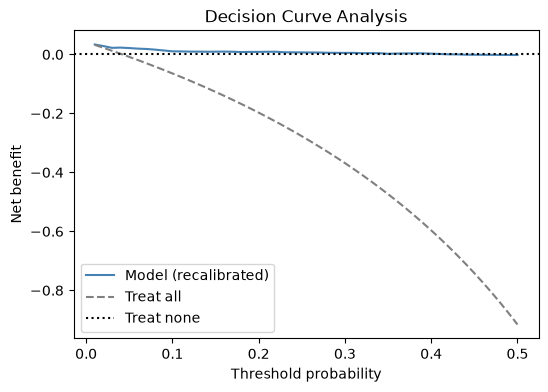

In [44]:
th = np.linspace(0.01, 0.50, 50)
y_arr = np.asarray(yte); n = len(y_arr); prev = y_arr.mean()
nb_m = [(((p_final>=t)&(y_arr==1)).sum()/n - ((p_final>=t)&(y_arr==0)).sum()/n*(t/(1-t))) for t in th]
nb_a = [prev - (1-prev)*(t/(1-t)) for t in th]

plt.figure(figsize=(6, 4))
plt.plot(th, nb_m, label='Model (recalibrated)', color='steelblue')
plt.plot(th, nb_a, '--', label='Treat all', color='gray')
plt.axhline(0, linestyle=':', color='black', label='Treat none')
plt.xlabel('Threshold probability')
plt.ylabel('Net benefit')
plt.legend()
plt.title('Decision Curve Analysis')
plt.show()

In [45]:
coef_tbl[coef_tbl['feature'].str.contains('cr|age|alb|bun|asa', regex=True)]

,feature,beta,OR
18,num__asa,0.236586,1.266917
23,num__age,-0.149174,0.861419
27,num__preop_bun,0.117859,1.125085
28,num__preop_alb,-0.111084,0.894863
30,num__preop_cr,-0.097020,0.907537
35,cat__optype_Biliary/Pancreas,-0.037937,0.962774
